# Perbandingan Model & Analisis Kesimpulan: KNN vs Random Forest

**Project 12 – Prediksi Perilaku Pembelian Pengunjung E-Commerce**  
**Dataset**: UCI Online Shoppers Purchasing Intention (12.330 sesi kunjungan, split 80:20 stratified, `random_state = 42`)  
**Target**: `Revenue` (1 = membeli, 0 = tidak membeli)  
**Bagian**: Anggota 4 – Perbandingan, Analisis Kesimpulan Bisnis & Jawaban Soal 6

## 1. Memuat Hasil Evaluasi Kedua Model

Memuat hasil evaluasi model **KNN (K = 5)** dan **Random Forest (100 trees)** yang telah dijalankan pada data test yang sama (`2.466` baris: `2.084` non-pembeli dan `382` pembeli) dari file `hasil_knn.json` dan `hasil_rf.json` di folder `output/`.

In [1]:
import sys, os, json
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from config import RANDOM_STATE, OUTPUT_DIR

sns.set_style("whitegrid")

with open(f"{OUTPUT_DIR}/hasil_knn.json") as f:
    hasil_knn = json.load(f)

with open(f"{OUTPUT_DIR}/hasil_rf.json") as f:
    hasil_rf = json.load(f)

print("Hasil KNN          :", hasil_knn)
print("Hasil Random Forest:", hasil_rf)

Hasil KNN          : {'model': 'KNN (K=5)', 'accuracy': 0.8719, 'precision': 0.6435, 'recall': 0.3874, 'f1': 0.4837, 'TN': 2002, 'FP': 82, 'FN': 234, 'TP': 148}
Hasil Random Forest: {'model': 'Random Forest (100 trees)', 'accuracy': 0.8978, 'precision': 0.7305, 'recall': 0.5393, 'f1': 0.6205, 'TN': 2008, 'FP': 76, 'FN': 176, 'TP': 206}


## 2. Tabel Perbandingan Metrik Evaluasi

Menggabungkan metrik evaluasi kedua model (**Accuracy, Precision, Recall, dan F1-score**) beserta rincian komponen Confusion Matrix (**TN, FP, FN, TP**) ke dalam satu tabel perbandingan.

In [2]:
from IPython.display import display

df_perbandingan = pd.DataFrame([hasil_knn, hasil_rf]).set_index("model")

df_metrik = df_perbandingan[["accuracy", "precision", "recall", "f1"]].rename(columns={
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1-score"
})

# Menambahkan baris selisih (Random Forest - KNN)
df_tabel = df_metrik.copy()
df_tabel.loc["Selisih (RF - KNN)"] = (df_metrik.loc["Random Forest (100 trees)"] - df_metrik.loc["KNN (K=5)"]).round(4)

print("=== Tabel Perbandingan Metrik Evaluasi ===")
display(df_tabel)

print("\n=== Rincian Komponen Confusion Matrix ===")
display(df_perbandingan[["TN", "FP", "FN", "TP"]])

=== Tabel Perbandingan Metrik Evaluasi ===


,Accuracy,Precision,Recall,F1-score
KNN (K=5),0.8719,0.6435,0.3874,0.4837
Random Forest (100 trees),0.8978,0.7305,0.5393,0.6205
Selisih (RF - KNN),0.0259,0.0870,0.1519,0.1368



=== Rincian Komponen Confusion Matrix ===


,TN,FP,FN,TP
model,,,,
KNN (K=5),2002,82,234,148
Random Forest (100 trees),2008,76,176,206


### Visualisasi Perbandingan Metrik (KNN vs Random Forest)

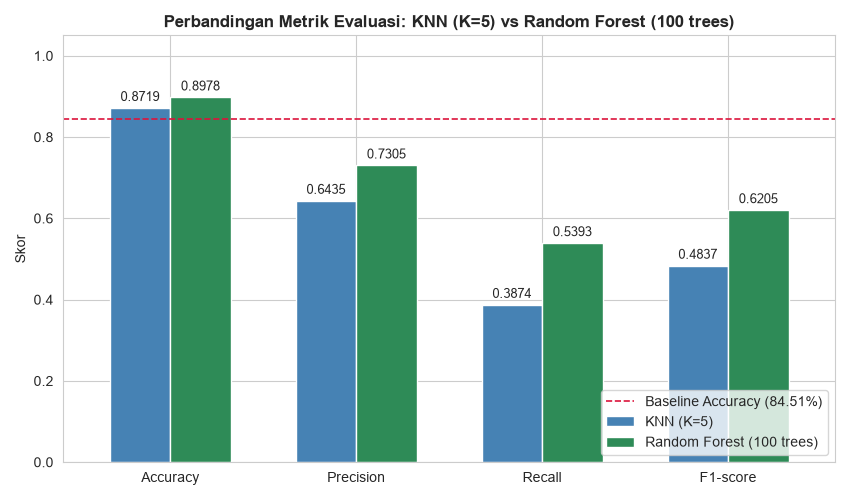

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5))
df_metrik.T.plot(kind="bar", ax=ax, color=["steelblue", "seagreen"], rot=0, width=0.65)

ax.set_title("Perbandingan Metrik Evaluasi: KNN (K=5) vs Random Forest (100 trees)", fontsize=12, fontweight="bold")
ax.set_ylabel("Skor")
ax.set_ylim(0, 1.05)
ax.axhline(0.8451, color="crimson", linestyle="--", linewidth=1.2, label="Baseline Accuracy (84.51%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", fontsize=9, padding=3)

ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/13_perbandingan_metrik.png", dpi=150)
plt.show()

## 3. Visualisasi Confusion Matrix Berdampingan

Menampilkan Confusion Matrix **KNN (K = 5)** dan **Random Forest (100 trees)** secara berdampingan dengan sumbu **Actual** (baris) dan **Predicted** (kolom).

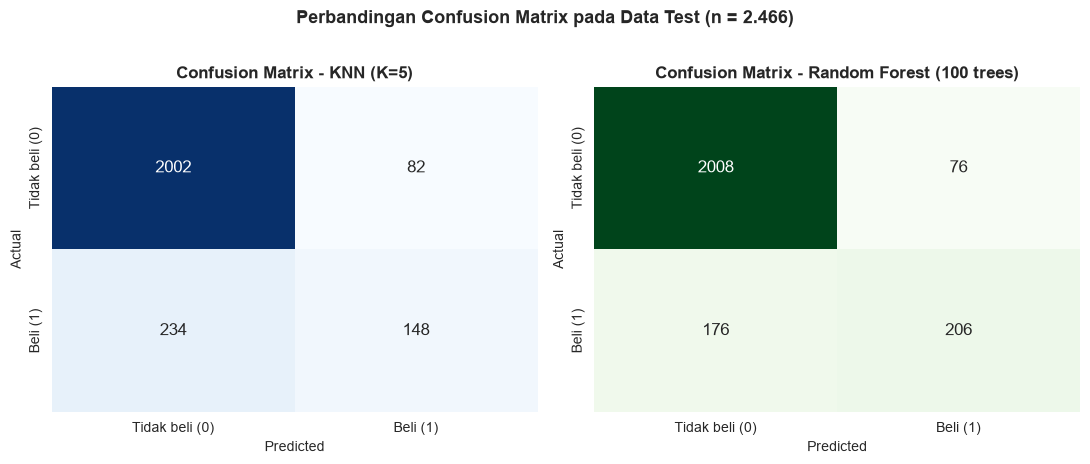

In [4]:
cm_knn = np.array([[hasil_knn["TN"], hasil_knn["FP"]],
                   [hasil_knn["FN"], hasil_knn["TP"]]])
cm_rf  = np.array([[hasil_rf["TN"],  hasil_rf["FP"]],
                   [hasil_rf["FN"],  hasil_rf["TP"]]])

labels = ["Tidak beli (0)", "Beli (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel Kiri: KNN
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=labels, yticklabels=labels, ax=axes[0], annot_kws={"size": 12})
axes[0].set_title("Confusion Matrix - KNN (K=5)", fontweight="bold")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Panel Kanan: Random Forest
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=labels, yticklabels=labels, ax=axes[1], annot_kws={"size": 12})
axes[1].set_title("Confusion Matrix - Random Forest (100 trees)", fontweight="bold")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.suptitle("Perbandingan Confusion Matrix pada Data Test (n = 2.466)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/14_cm_perbandingan.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Analisis Perbandingan & Kesimpulan Bisnis

### 4.1 Analisis Perbandingan Kedua Model
Berdasarkan tabel evaluasi dan visualisasi confusion matrix pada `2.466` data uji (`2.084` tidak membeli dan `382` membeli):

1. **Accuracy (`89,78%` vs `87,19%`)**:
   - Karena dataset memiliki ketimpangan kelas (*class imbalance*) di mana `84,51%` pengunjung tidak membeli, model naif yang selalu menebak "Tidak beli" saja sudah memperoleh akurasi `84,51%`.
   - KNN hanya meningkatkan akurasi sebesar `+2,68%` di atas baseline, sedangkan Random Forest meningkatkan akurasi sebesar `+5,27%` di atas baseline.
2. **Precision (`73,05%` vs `64,35%`)**:
   - Dari seluruh pengunjung yang diprediksi akan membeli oleh Random Forest (`206 + 76 = 282` orang), sebanyak `206` orang benar-benar membeli (**73,05%**).
   - Pada KNN, dari `148 + 82 = 230` orang yang diprediksi membeli, hanya `148` orang yang benar-benar membeli (**64,35%**). Random Forest menghasilkan lebih sedikit *False Positive* (`76` vs `82`).
3. **Recall (`53,93%` vs `38,74%`) — Perbedaan Paling Signifikan**:
   - Dari total `382` pengunjung yang benar-benar membeli di data uji, **Random Forest berhasil menemukan `206` pembeli** (`FN = 176` terlewat).
   - Sebaliknya, **KNN hanya menemukan `148` pembeli** (`FN = 234` terlewat).
   - Random Forest mampu menjaring **58 calon pembeli lebih banyak** (`+15,19%` poin recall) dibandingkan KNN.
4. **F1-Score (`62,05%` vs `48,37%`)**:
   - F1-score merangkum keseimbangan antara Precision dan Recall. Random Forest unggul jauh dengan selisih `+13,68%`.

---

### 4.2 Kesimpulan: Model Mana yang Lebih Cocok untuk Kebutuhan Perusahaan?
**Model yang lebih cocok untuk perusahaan e-commerce adalah Random Forest (100 trees).**

**Alasan Teknis & Bisnis:**
- **Menangkap Lebih Banyak Calon Pembeli (Recall Tinggi):** Dalam bisnis e-commerce, melewatkan calon pembeli potensial (*False Negative*) berarti kehilangan potensi transaksi (*lost revenue*). Random Forest menekan jumlah *False Negative* dari `234` (pada KNN) menjadi `176`.
- **Promosi Lebih Tepat Sasaran (Precision Tinggi):** Ketika perusahaan memberikan intervensi pemasaran (misalnya *pop-up* diskon atau pengingat *checkout*) kepada pengunjung yang diprediksi membeli, Random Forest lebih akurat sehingga biaya promosi tidak banyak terbuang pada pengunjung yang tidak berniat membeli (*False Positive* hanya `76`).
- **Tangguh terhadap Dimensi & Skala Fitur:** Dataset memiliki 28 fitur (gabungan numerik dengan rentang sangat beragam dan fitur kategorikal hasil *one-hot encoding*). Random Forest bekerja dengan pembelahan pohon (*decision threshold*) sehingga tidak terpengaruh perbedaan skala atribut dan mampu menangkap interaksi fitur non-linear dengan baik, serta memberikan informasi **Feature Importance** (`PageValues`, `ExitRates`, `ProductRelated_Duration`) yang berguna bagi tim bisnis.

## 5. Jawaban Pertanyaan Pemahaman (Soal 6)

> **Soal 6:** *Jika tujuan perusahaan adalah menemukan sebanyak mungkin calon pembeli, metrik evaluasi apa yang perlu diperhatikan?*

**Jawaban:**
Metrik evaluasi utama yang harus diperhatikan oleh perusahaan adalah **Recall** (disebut juga *Sensitivity* atau *True Positive Rate*) pada kelas positif (`Revenue = 1`).

$$\text{Recall} = \frac{TP}{TP + FN}$$

**Penjelasan:**
1. **Fokus pada Penemuan Calon Pembeli ($TP$) dan Meminimalkan Pembeli yang Terlewat ($FN$):**
   - **True Positive ($TP$)** adalah pengunjung yang benar-benar membeli dan berhasil dikenali oleh model.
   - **False Negative ($FN$)** adalah pengunjung yang sebenarnya berniat membeli, namun salah diprediksi sebagai "tidak membeli" sehingga terlewat oleh sistem.
   - Semakin tinggi nilai **Recall**, semakin sedikit calon pembeli yang terlewat ($FN$ semakin kecil).
2. **Pertimbangan Biaya Kesalahan Bisnis (*Cost of Error*):**
   - Jika terjadi **False Positive ($FP$)** (pengunjung tidak beli tetapi diprediksi beli), perusahaan paling hanya mengeluarkan biaya kecil seperti menampilkan *pop-up* promo atau mengirim notifikasi penawaran.
   - Namun jika terjadi **False Negative ($FN$)** (calon pembeli potensial tidak terdeteksi), perusahaan kehilangan kesempatan untuk mendorong konversi transaksi yang nilainya jauh lebih besar.
3. **Bukti pada Hasil Eksperimen:**
   - Pada hasil pengujian kelompok kami, meskipun akurasi kedua model terlihat sama-sama tinggi (`87,19%` pada KNN dan `89,78%` pada Random Forest), melihat metrik **Recall** mengungkap perbedaan kemampuan yang sangat tajam: KNN hanya mampu mendeteksi **38,74%** calon pembeli (`148` dari `382`), sedangkan Random Forest mampu mendeteksi **53,93%** calon pembeli (`206` dari `382`). Apabila perusahaan ingin meningkatkan Recall lebih lanjut, perusahaan juga dapat menurunkan *probability threshold* prediksi di bawah `0.5` atau menerapkan `class_weight='balanced'`.